# How does an animal learn what comes before a reward?

A mouse hears a short tone, and 1.25 s later a drop of sucrose arrives. At first the
tone means nothing. Over many pairings the mouse starts licking during the tone,
before the sucrose comes, and dopamine in the nucleus accumbens (NAc) starts
responding to the tone itself. Both signals show that the animal has learned that
the tone predicts reward.

This notebook follows that learning trial by trial in real data from
[DANDI:001632](https://dandiarchive.org/dandiset/001632/draft) (Burke et al., 2026,
Nature Neuroscience, [doi:10.1038/s41593-026-02206-2](https://doi.org/10.1038/s41593-026-02206-2)).
Head-fixed mice received cue-sucrose pairings while dopamine release in the NAc was
recorded with the dLight1.3b sensor by fiber photometry. Three cohorts differed only
in the mean time between pairings (inter-trial interval, ITI): 60 s, 600 s or 3600 s.
Each session lasted about an hour (two hours for 3600 s), so the cohorts received
50, 6 or 2 pairings per day.

The question here: does learning depend on how many pairings an animal experiences,
or on how they are spaced in time?

The pipeline is split into four scripts that this notebook runs in order:

1. `01_load_data.py`: fetch every session of the three dopamine cohorts from DANDI
2. `02_preprocess.py`: quality checks and a raw-data view
3. `03_analyze_cue_reward_learning.py`: per-trial licking and dopamine measures, learning trial per mouse
4. `04_visualize.py`: summary figures

In [1]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

HERE = Path.cwd()
DATA = HERE / "data"
FIG = HERE / "figures"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Load the data

Each NWB file is small (0.3 to 14 MB), so it is fetched in a single HTTP request and
read with h5py. Files are cached as `data/*.npz`, so re-running skips the download.
Event codes in `acquisition/eventLog`: 15 = CS+ tone onset, 10 = sucrose solenoid,
5 = lick onset on the sucrose spout. Dopamine: `processing/photometry/photometry_dff`.

In [2]:
importlib.import_module("01_load_data").main()

148 sessions from 18 mice


Loading sessions:   0%|          | 0/148 [00:00<?, ?it/s]

Loading sessions:   2%|▏         | 3/148 [00:00<00:06, 23.25it/s]

Loading sessions:   4%|▍         | 6/148 [00:00<00:05, 24.53it/s]

Loading sessions:   6%|▌         | 9/148 [00:00<00:05, 25.82it/s]

...

Loading sessions:  84%|████████▍ | 125/148 [00:02<00:00, 62.05it/s]

Loading sessions:  89%|████████▉ | 132/148 [00:03<00:00, 62.39it/s]

Loading sessions:  94%|█████████▍| 139/148 [00:03<00:00, 62.12it/s]

Loading sessions:  99%|█████████▊| 146/148 [00:03<00:00, 62.04it/s]

Loading sessions: 100%|██████████| 148/148 [00:03<00:00, 44.04it/s]

## 2. Quality checks and raw data

All 148 sessions (18 mice) have one sucrose delivery 1.25 s after every tone.
Photometry is sampled at about 120 Hz (130 Hz for the 3600 s cohort). One session
has a 15-minute NaN stretch away from any cue, one has a single dropped sample,
and in one session (60sD-F8 day02a, recorded before a software crash) no licks
were logged. Its licking is treated as missing.

       n_cs           fs_hz             max_gap_s           n_nan         cs_reward_delay_min       cs_reward_delay_max       
        min max         min         max       min       max   min     max                 min   max                 min    max
group                                                                                                                         
3600sD    2   2  129.802358  130.054089  0.007689  0.008153     0  115299                1.25  1.25                1.25  1.250
600sD     6   6  120.294253  120.299523  0.008313  0.016295     0       0                1.25  1.25                1.25  1.251
60sD     11  50  120.293806  120.481931  0.008300  0.008314     0       0                1.25  1.25                1.25  1.251
session_description
Conditioning session for 600 s ITI mouse                                  56
Conditioning session for 60 s ITI mouse                                   48
Conditioning session for 3600 s ITI mouse                       

sessions  pairings
group  subject                      
3600sD 3600sD-F1         9        18
       3600sD-F2         8        16
       3600sD-F3         9        18
       3600sD-M1         8        16
       3600sD-M2         8        16
600sD  600sD-F10         8        48
       600sD-F6          8        48
       600sD-F7          8        48
       600sD-F8          8        48
       600sD-F9          8        48
       600sD-M8          8        48
       600sD-M9          8        48
60sD   60sD-F11          8       400
       60sD-F7           8       400
       60sD-F8           9       411
       60sD-F9           8       400
       60sD-M7           8       400
       60sD-M8           9       450

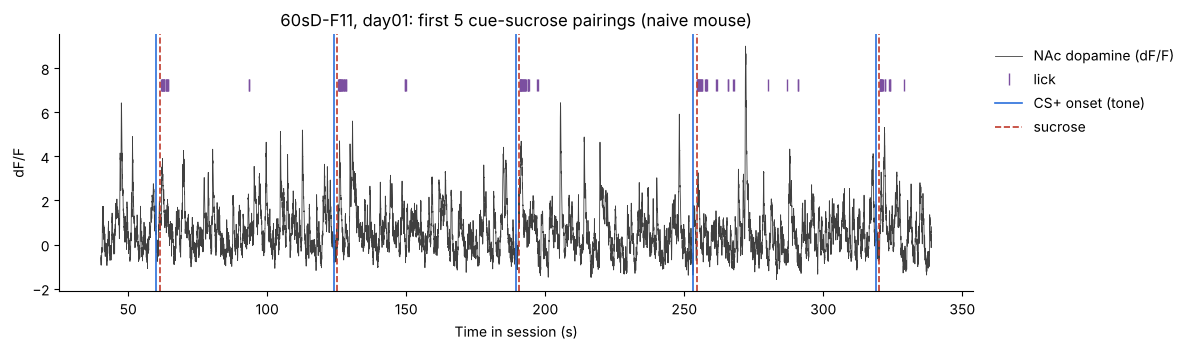

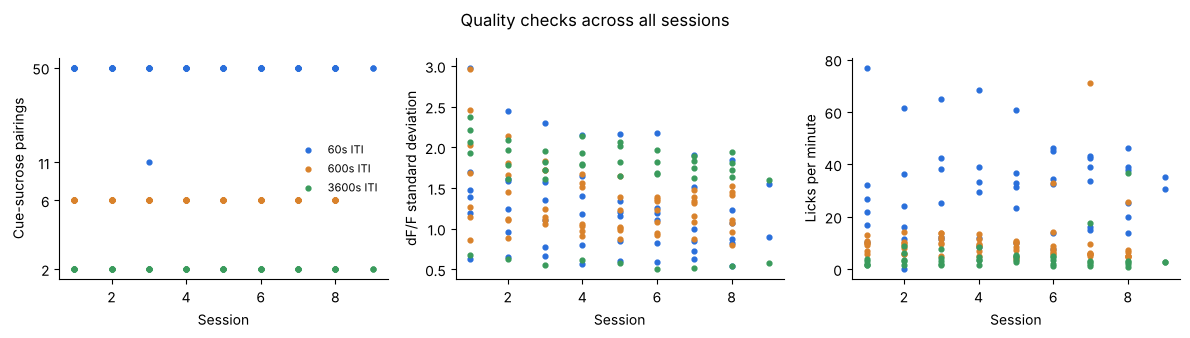

In [3]:
importlib.import_module("02_preprocess").main()
sessions = pd.read_csv(DATA / "sessions.csv")
sessions.groupby(["group", "subject"])["n_cs"].agg(sessions="count", pairings="sum")

The first five pairings for a naive 60 s ITI mouse. Dopamine rises after the
sucrose and the mouse licks only once the sucrose is there. The tone itself
triggers little.

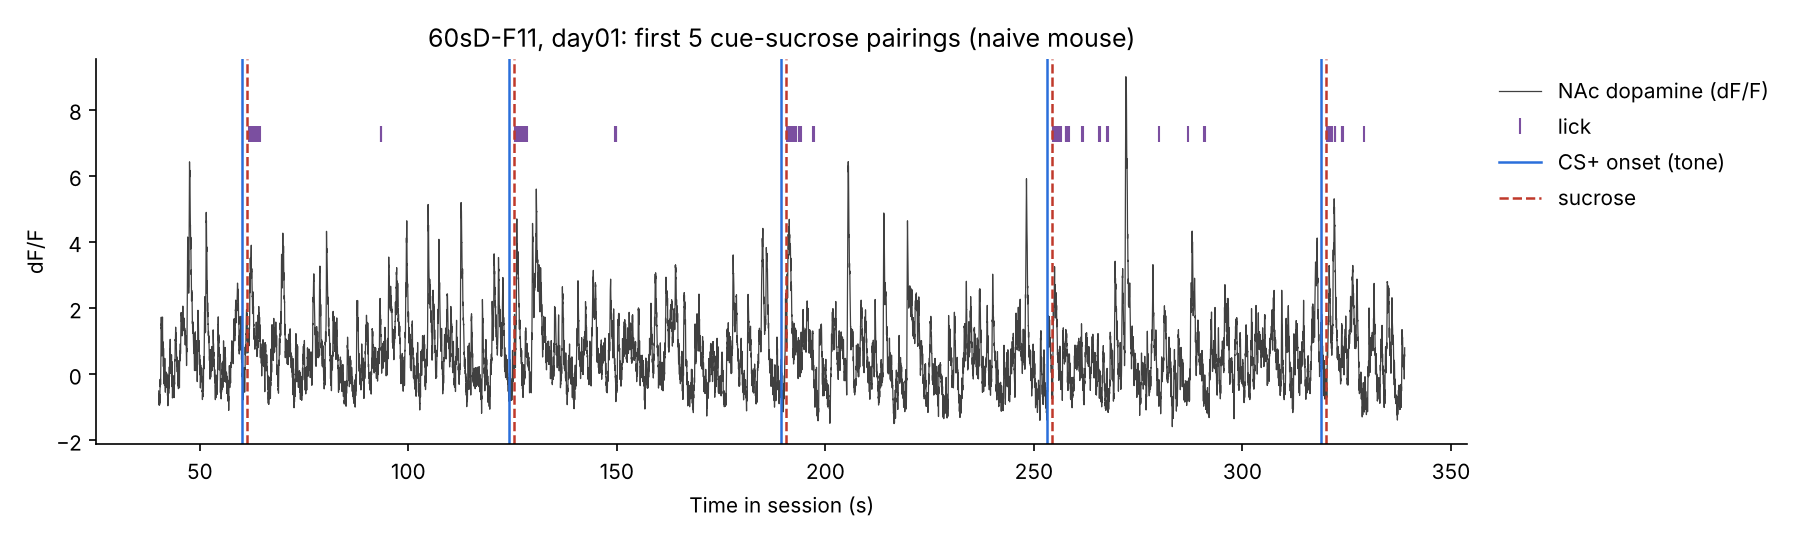

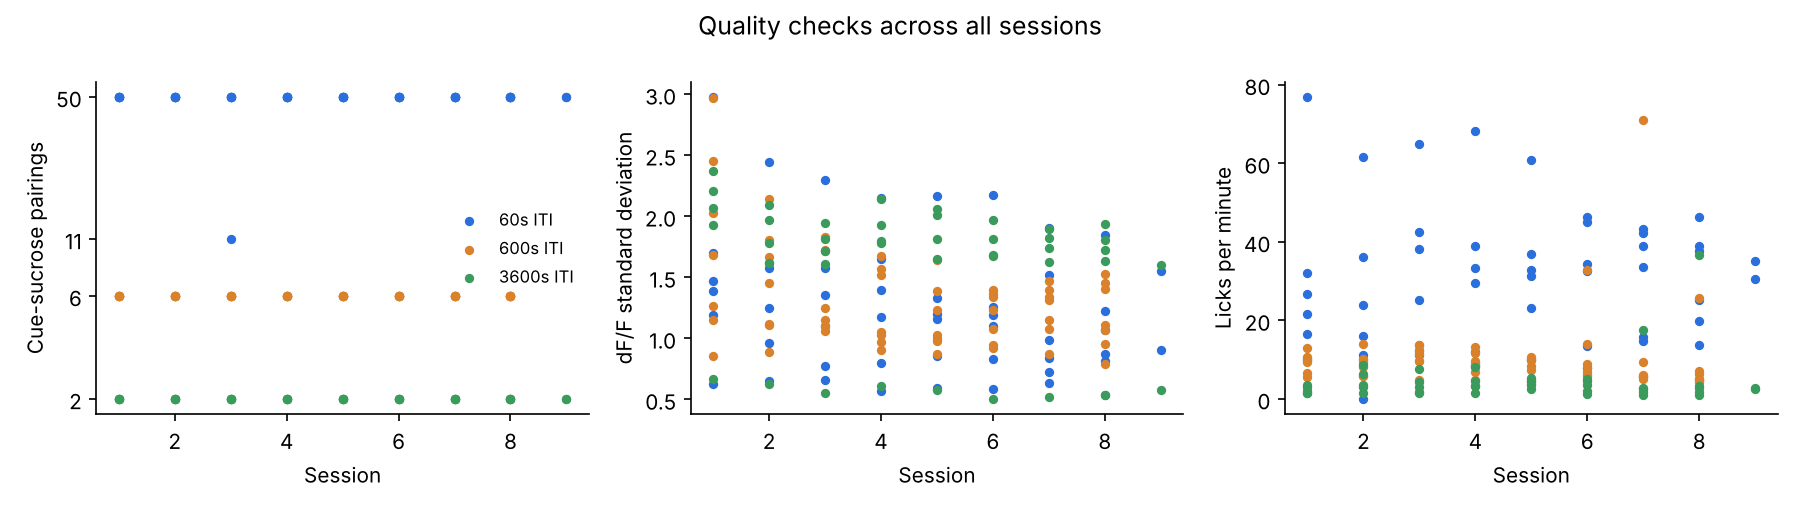

In [4]:
display(Image(FIG / "01_raw_session.png"))
display(Image(FIG / "02_qc.png"))

## 3. Measure learning on every trial

For each tone presentation:

- anticipatory licking: lick rate during the 1.25 s tone-to-sucrose delay minus the
  rate in the 1.25 s before the tone
- dopamine cue response: mean dF/F 0 to 0.5 s after tone onset minus the 1 s pre-tone baseline
- dopamine reward response: mean dF/F 0 to 0.5 s after sucrose minus the same baseline

The trial where each mouse learns is taken as the elbow of the cumulative curve of
each measure: the point where the running sum bends upward. A second criterion
(5-trial running mean reaches half the mouse's final level) is computed as a check.

In [5]:
importlib.import_module("03_analyze_cue_reward_learning").main()
learning = pd.read_csv(DATA / "learning.csv")
learning.round(2)

Sessions:   0%|          | 0/148 [00:00<?, ?it/s]

Sessions:   1%|          | 1/148 [00:00<01:12,  2.02it/s]

Sessions:   1%|▏         | 2/148 [00:00<00:44,  3.27it/s]

Sessions:   2%|▏         | 3/148 [00:00<00:33,  4.34it/s]

Sessions:   3%|▎         | 4/148 [00:00<00:28,  5.09it/s]

...

Sessions:  98%|█████████▊| 145/148 [00:14<00:00, 13.98it/s]

Sessions:  99%|█████████▉| 147/148 [00:14<00:00, 14.02it/s]

Sessions: 100%|██████████| 148/148 [00:14<00:00, 10.20it/s]

group                          3600sD       600sD         60sD
anticipatory_lick_hz count  84.000000  335.000000  2410.000000
                     mean    2.857143    2.949254     2.253610
                     std     2.402523    2.088389     2.396527
                     min     0.000000    0.000000    -4.000000
                     25%     0.000000    1.600000     0.000000
                     50%     2.400000    3.200000     1.600000
                     75%     4.800000    4.800000     4.800000
                     max     7.200000    8.000000     7.200000
da_cue               count  84.000000  335.000000  2460.000000
                     mean   17.565569    7.148474     2.804466
                     std    10.671616    4.137641     2.817462
                     min     0.314026   -1.451328    -7.579946
                     25%     6.984683    4.161908     0.699302
                     50%    18.550712    6.706025     2.071679
                     75%    26.215270    9.842777     4

,subject,group,mean_iti_s,n_trials,learned_trial_lick,lick_before,lick_after,learned_trial_lick_half,learned_trial_da,da_before,da_after,learned_trial_da_half,da_cue_trial1,learned_time_lick_h,learned_time_da_h
0,3600sD-F1,3600sD,3600.0,18,9,0.70,4.96,7,11,1.93,3.31,2,0.31,9.00,11.00
1,3600sD-F2,3600sD,3600.0,16,6,0.32,3.93,3,4,14.15,31.36,1,9.57,6.00,4.00
2,3600sD-F3,3600sD,3600.0,18,9,1.30,6.00,7,8,13.22,25.49,3,7.13,9.00,8.00
3,3600sD-M1,3600sD,3600.0,16,11,1.12,2.53,2,11,14.74,23.17,1,2.09,11.00,11.00
4,3600sD-M2,3600sD,3600.0,16,9,0.60,4.80,6,9,14.06,25.97,2,6.53,9.00,9.00
5,600sD-F10,600sD,600.0,48,23,1.16,2.92,6,21,3.85,5.35,1,0.07,3.83,3.50
6,600sD-F6,600sD,600.0,48,14,0.25,3.38,11,19,4.71,8.91,5,1.55,2.33,3.17
7,600sD-F7,600sD,600.0,48,12,0.29,2.98,10,8,9.38,13.39,1,-0.09,2.00,1.33
8,600sD-F8,600sD,600.0,48,18,0.80,4.88,14,9,4.07,10.05,4,0.63,3.00,1.50
9,600sD-F9,600sD,600.0,48,18,1.13,3.05,7,3,2.28,5.00,1,0.09,3.00,0.50


## 4. What learning looks like

One mouse per cohort (the one with the median dopamine learning trial). In every
cohort the tone-evoked dopamine response (left band at 0 s) grows from nothing,
and licking spreads backward from the sucrose into the delay period.
The cyan dotted line marks the learning trial.

/home/user/dandi-showcase-runs/reward_c/04_visualize.py:119: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(per_mouse, axis=0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/user/dandi-showcase-runs/reward_c/04_visualize.py:119: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(per_mouse, axis=0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


anticipatory licking / elbow of cumulative curve: slope -0.632 +/- 0.102, r -0.841, p 1.2e-05
dopamine cue response / elbow of cumulative curve: slope -0.698 +/- 0.097, r -0.874, p 2.2e-06
anticipatory licking / running mean reaches half of asymptote: slope -0.366 +/- 0.204, r -0.409, p 0.092
dopamine cue response / running mean reaches half of asymptote: slope -0.668 +/- 0.148, r -0.748, p 0.00036


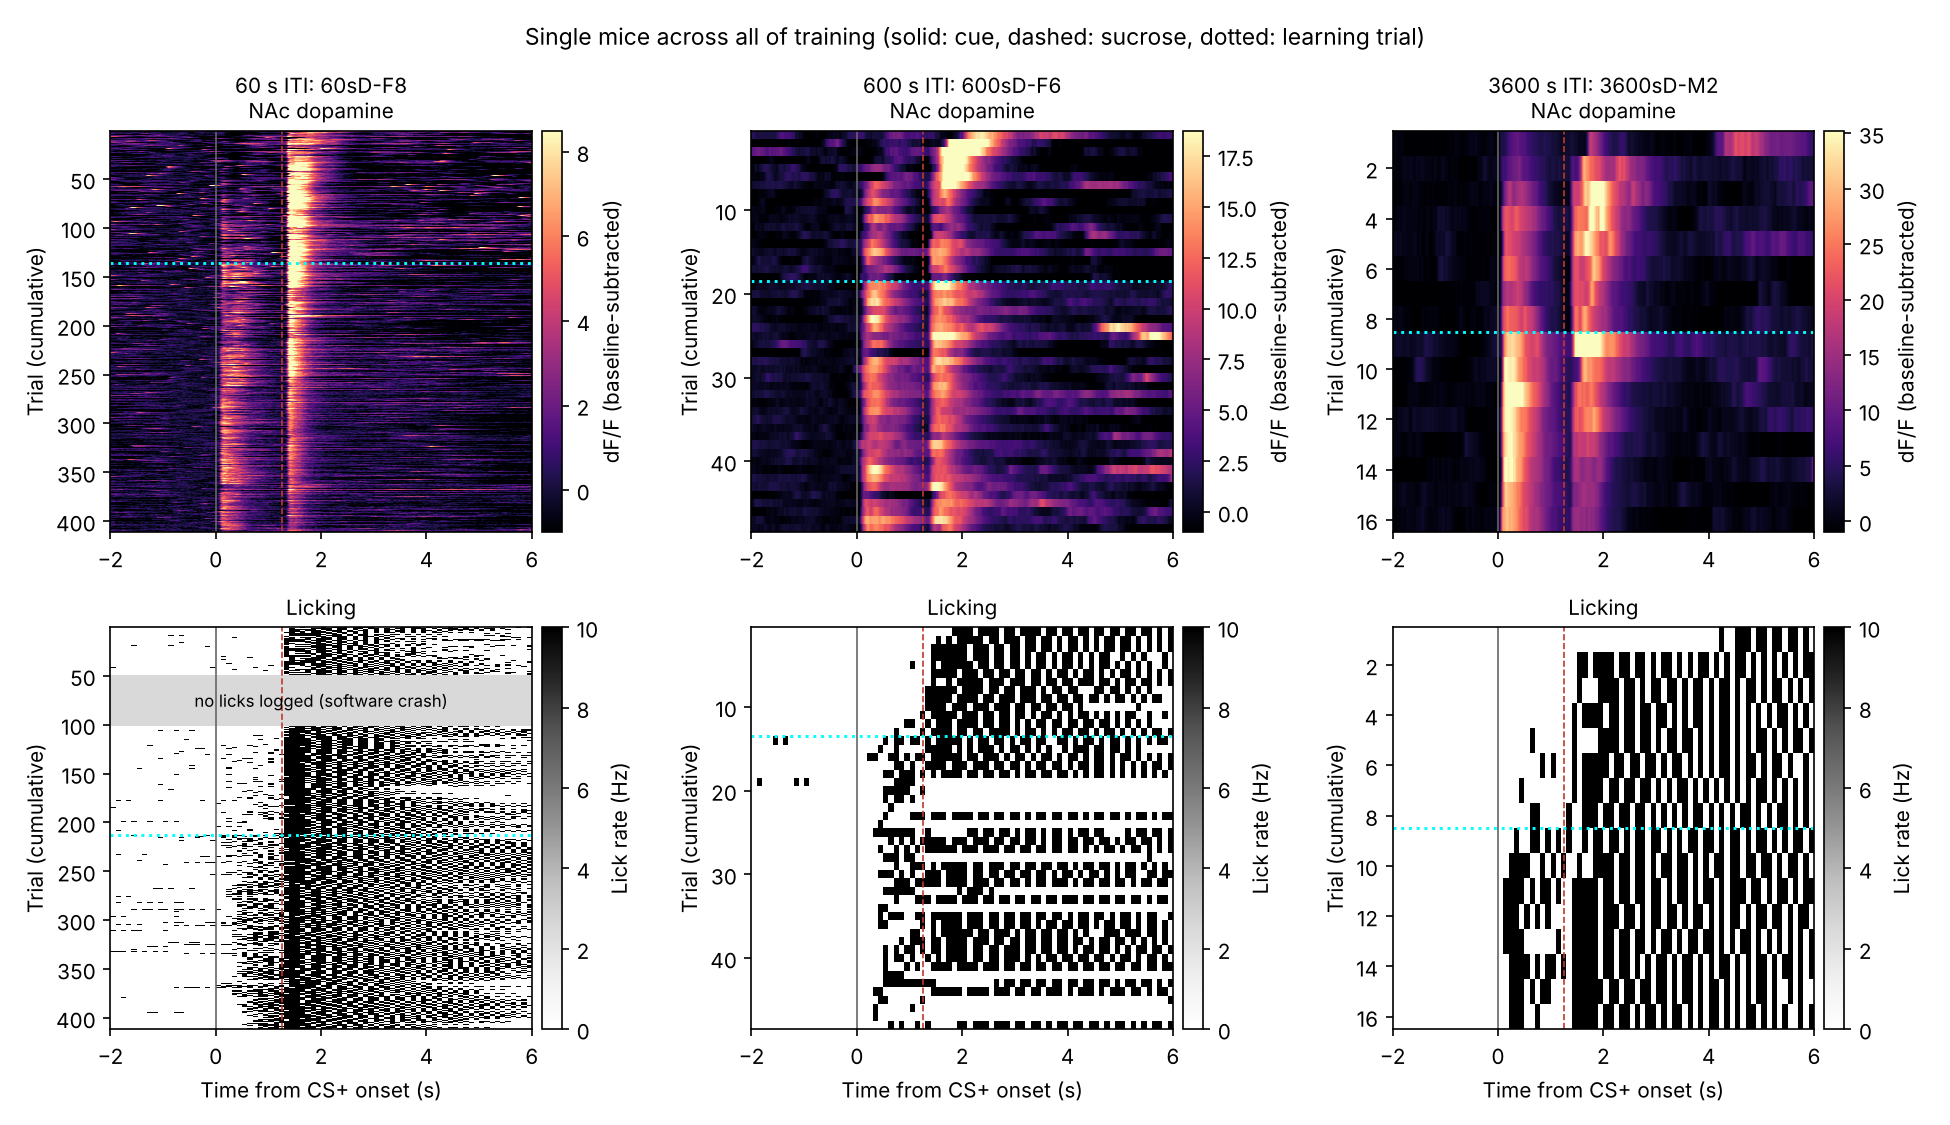

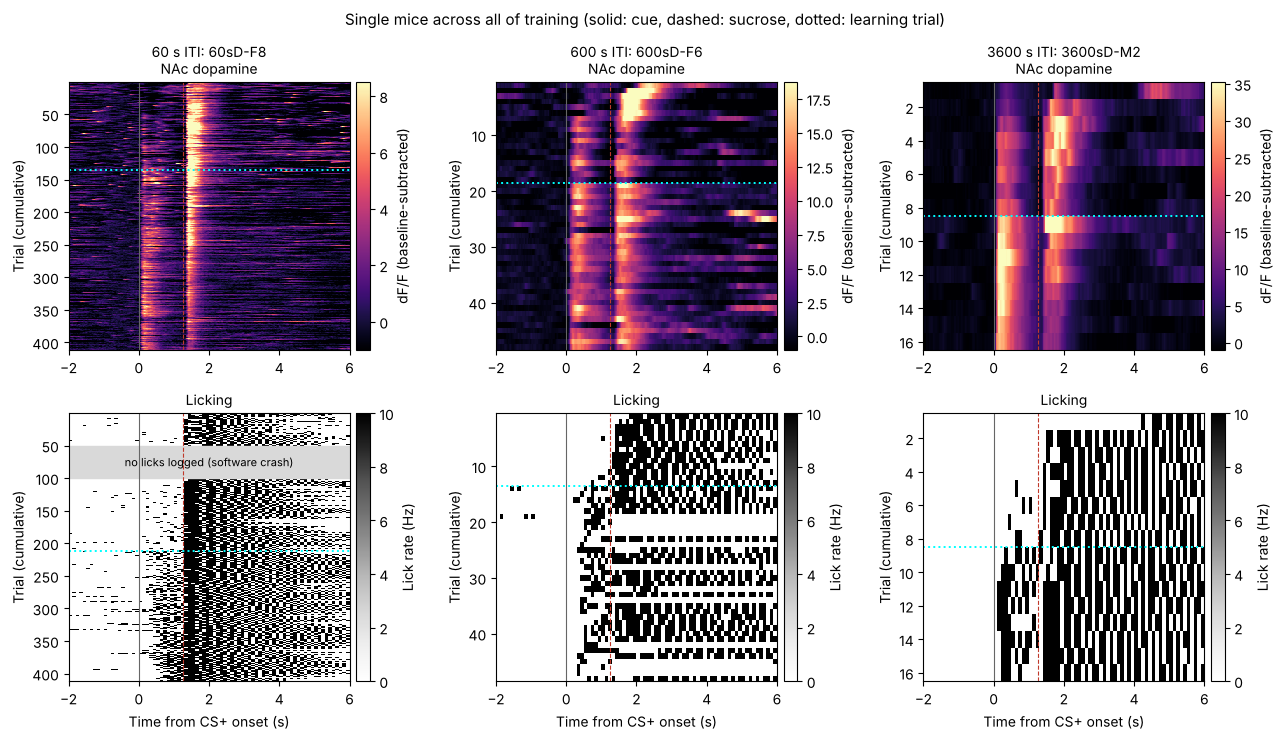

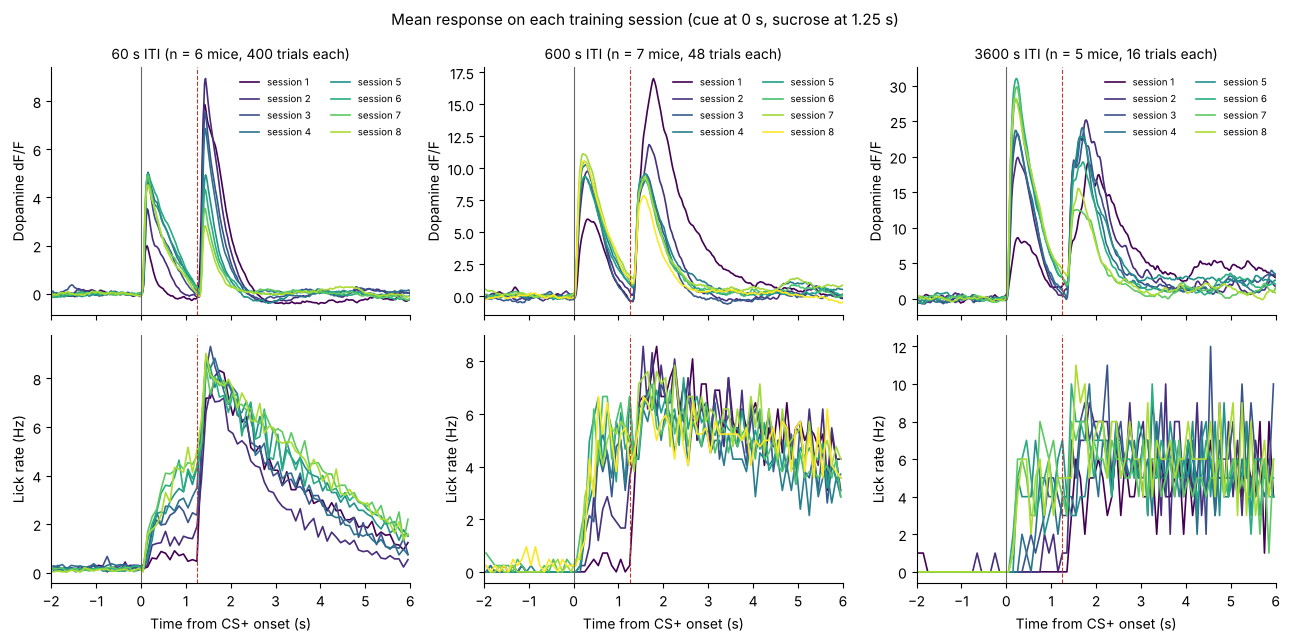

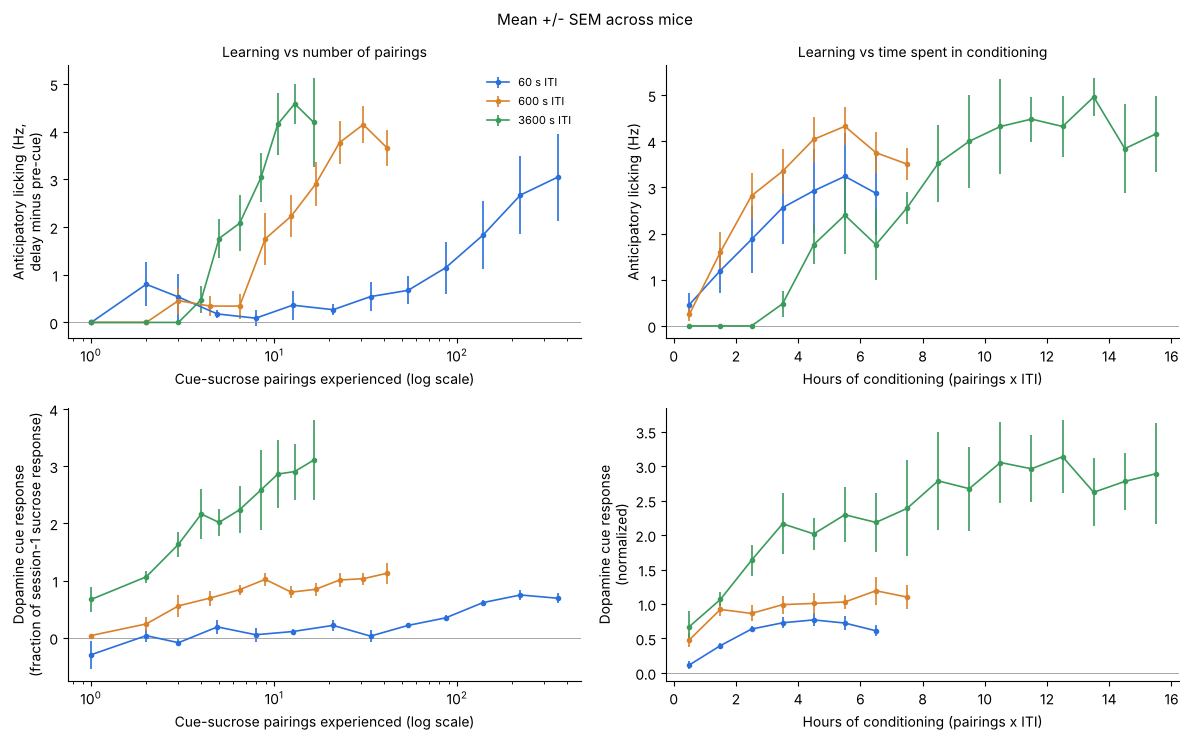

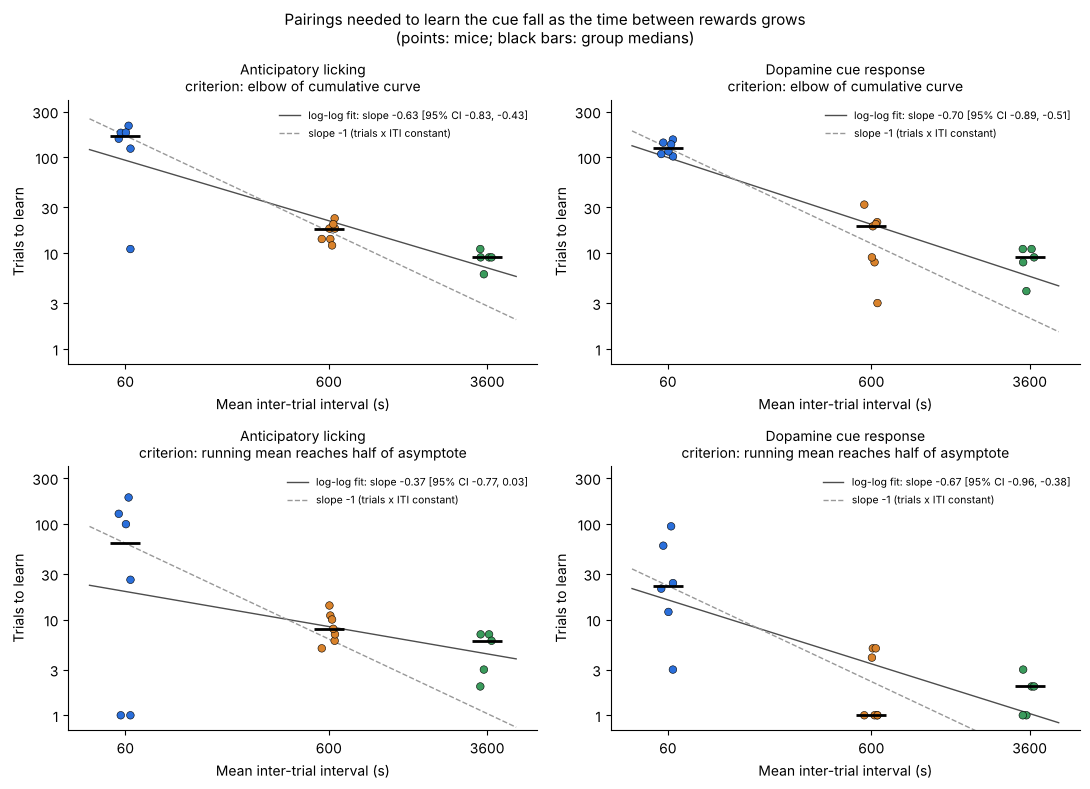

In [6]:
importlib.import_module("04_visualize").main()
display(Image(FIG / "03_example_heatmaps.png"))

Averaged per session, the dopamine response moves from the sucrose to the tone.
The cue response grows while the sucrose response shrinks, which is the pattern
expected when the reward becomes predicted. Anticipatory licking between 0 and
1.25 s grows along with it.

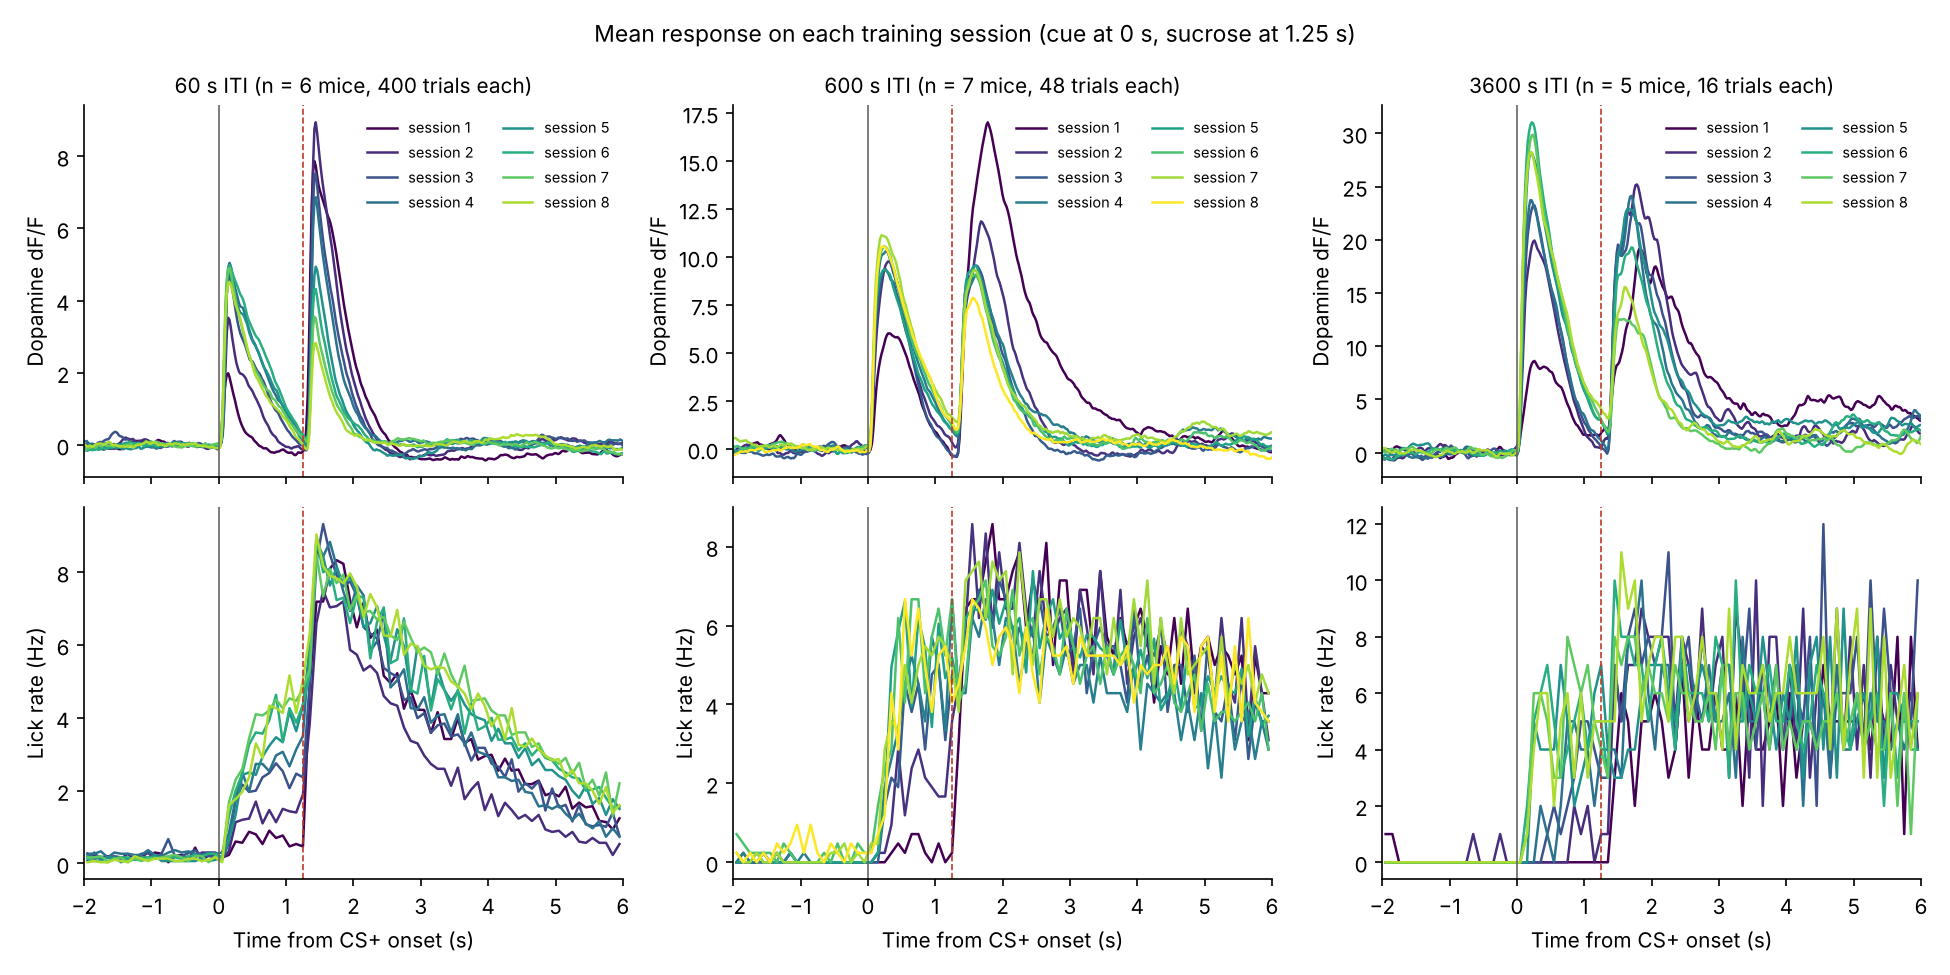

In [7]:
display(Image(FIG / "04_peth_by_session.png"))

## 5. Pairings or time?

Plotted against the number of pairings (left), the three cohorts learn at very
different points: the 60 s ITI mice need hundreds of pairings, the 600 s ITI
mice tens, the 3600 s ITI mice fewer than ten. Plotted against hours of
conditioning (right; pairings times ITI), the 60 s and 600 s curves overlap.
The 3600 s mice learn in the fewest pairings but over more hours.

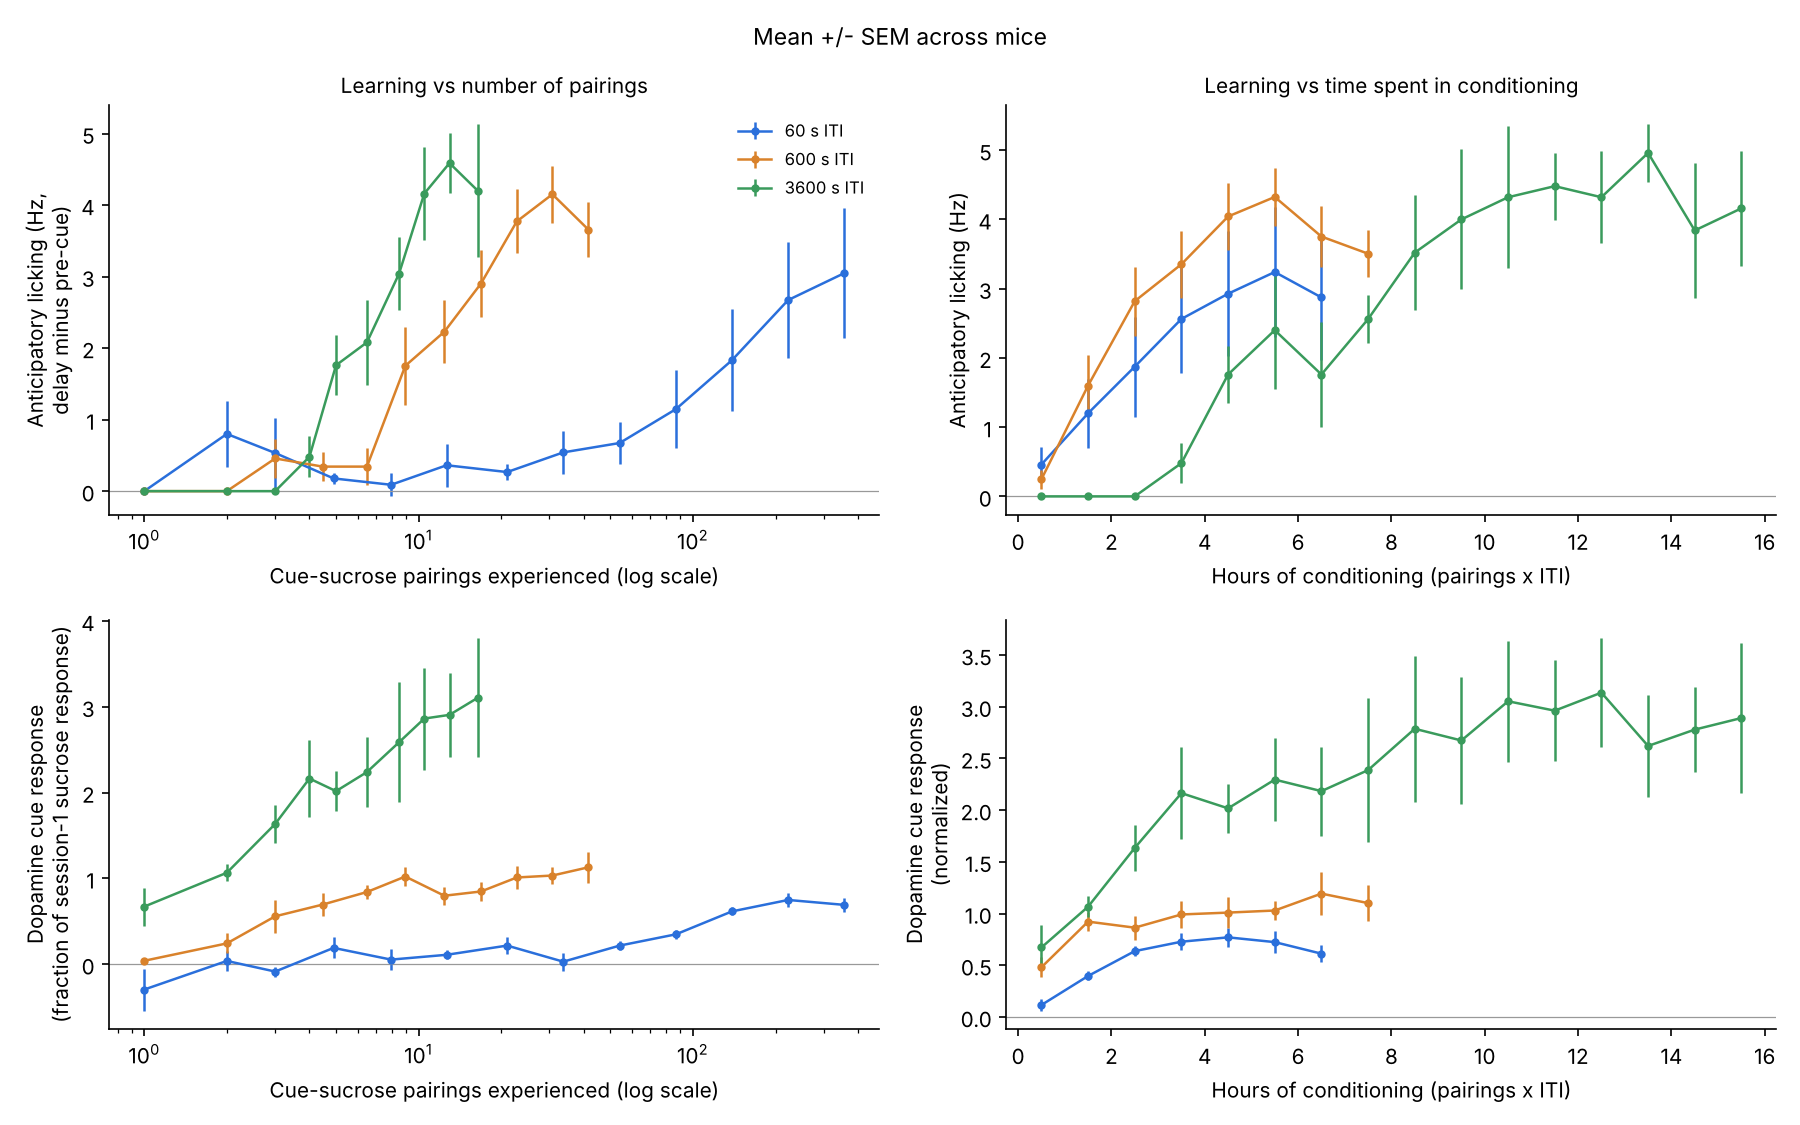

In [8]:
display(Image(FIG / "05_learning_curves.png"))

In [9]:
summary = learning.groupby("group")[
    ["learned_trial_lick", "learned_trial_da", "learned_time_lick_h", "learned_time_da_h"]
].median().loc[["60sD", "600sD", "3600sD"]]
summary.columns = ["pairings to learn (licking)", "pairings to learn (dopamine)",
                   "hours to learn (licking)", "hours to learn (dopamine)"]
summary.round(1)

,pairings to learn (licking),pairings to learn (dopamine),hours to learn (licking),hours to learn (dopamine)
group,,,,
60sD,168.0,125.5,2.8,2.1
600sD,18.0,19.0,3.0,3.2
3600sD,9.0,9.0,9.0,9.0


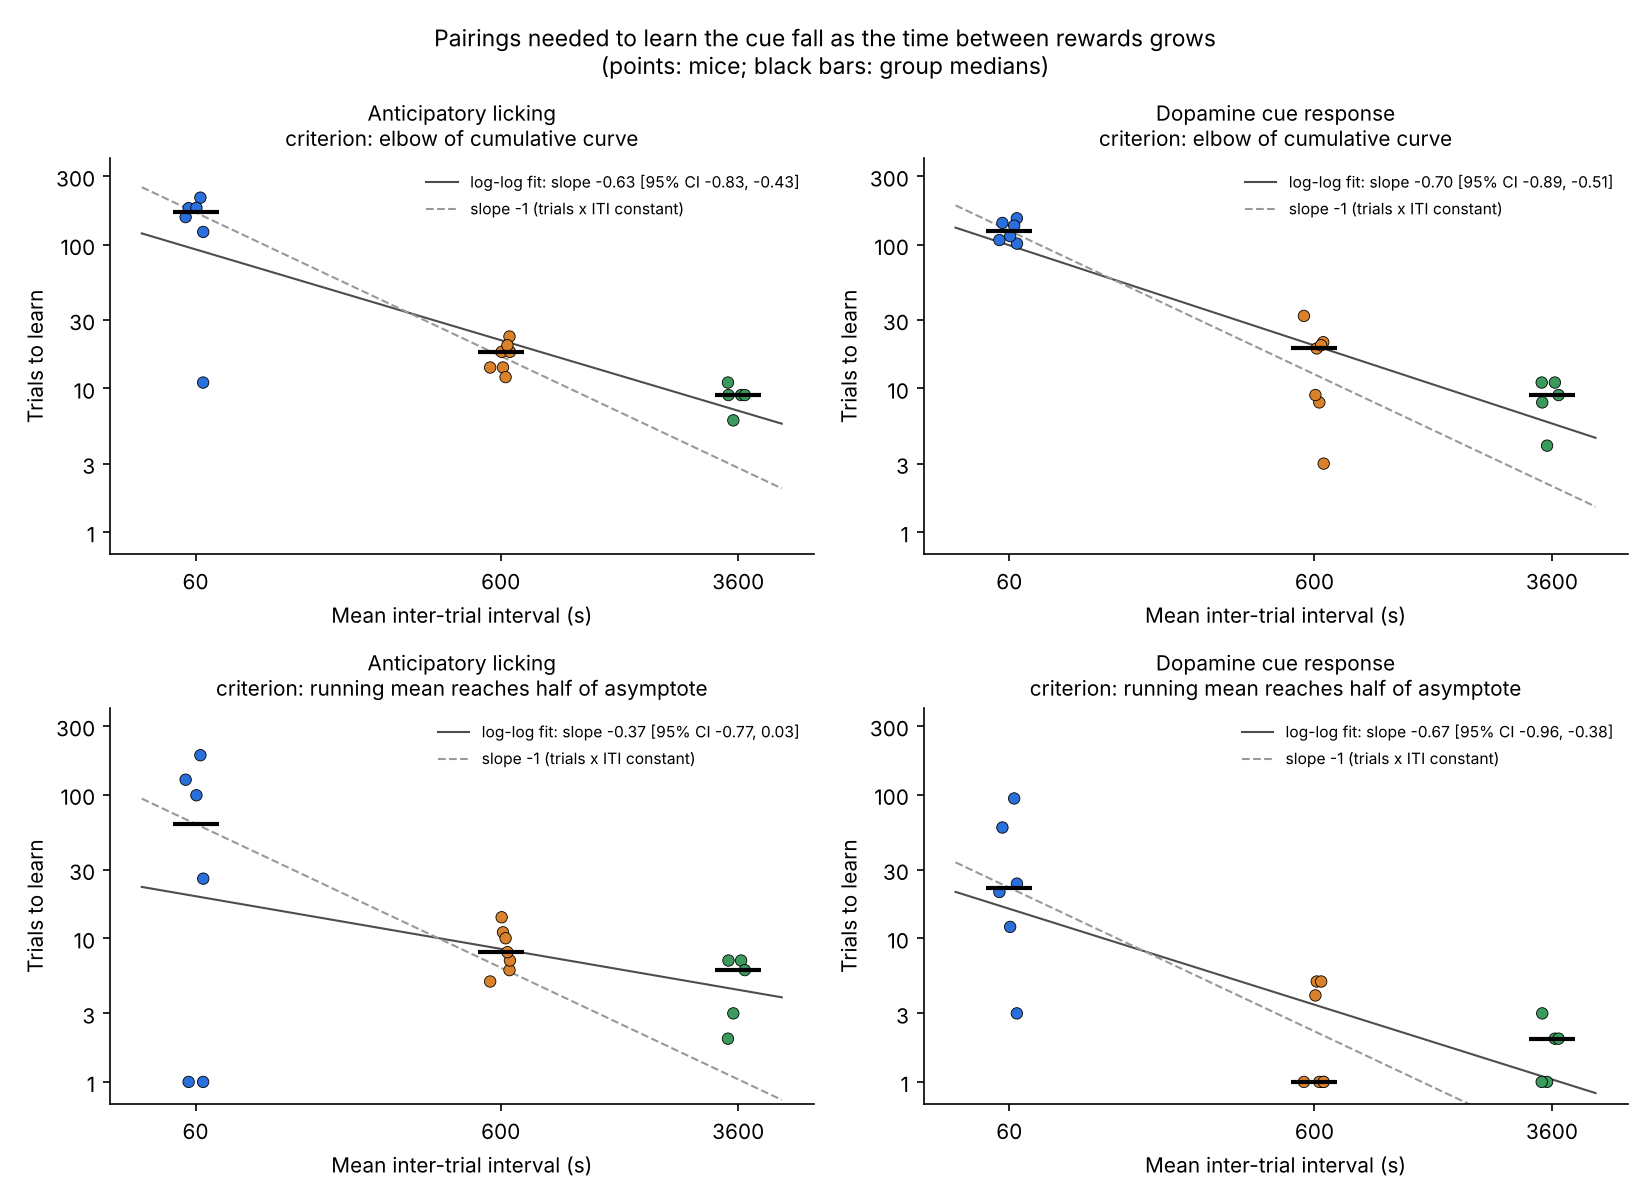

In [10]:
display(Image(FIG / "06_learned_trial_vs_iti.png"))

## Results

What the animal learns. In all 18 mice the dopamine response to the tone grew over
training (it was absent at the start in the 60 s and 600 s cohorts), and 16 of 18
mice developed clear licking during the tone. As the cue response grows, the dopamine response to the
sucrose itself shrinks (figure 4). The reward-evoked signal transfers to the event
that predicts it.

How fast depends on the spacing between rewards. Using the elbow criterion,
median pairings to learn were:

| ITI | licking | dopamine | hours (licking) | hours (dopamine) |
|---|---|---|---|---|
| 60 s (6 mice) | 168 | 126 | 2.8 | 2.1 |
| 600 s (7 mice) | 18 | 19 | 3.0 | 3.2 |
| 3600 s (5 mice) | 9 | 9 | 9 | 9 |

Going from 60 s to 600 s (ten times longer between rewards) cut the number of
pairings needed by about ninefold for licking and sevenfold for dopamine, while
the conditioning time needed stayed at about 2 to 3 hours. Learning per pairing
grew roughly in proportion to the time between pairings, consistent with the
source paper's conclusion.

Across all three cohorts, the log-log slope of pairings-to-learn against ITI was
-0.63 (95% CI -0.83 to -0.43) for licking and -0.70 (-0.89 to -0.51) for dopamine.
A slope of -1 would mean exact proportionality. The 3600 s cohort pulls the slope
toward zero: those mice learned in fewer pairings but over more hours.

Caveats:

- The 3600 s mice got only 2 pairings a day and 16 to 18 in total, so the learning
  trial is poorly resolved at the low end. By the half-asymptote criterion their
  dopamine cue response reached half its final size within 1 to 3 pairings.
- Several 3600 s mice already showed a dopamine response to the tone on the very
  first trial (mean 5.1 dF/F units versus about 0 in the other cohorts), before
  any pairing. A tone after an hour of silence likely evokes a novelty response,
  which confounds the early dopamine measure for that cohort.
- Two 60 s mice (F9, F11) developed little anticipatory licking (at most 0.6 Hz
  after the elbow), so their licking learning trials are not meaningful. They are
  kept in all statistics.
- The half-asymptote criterion gives a weaker, non-significant licking relationship
  (slope -0.37, p = 0.09), mainly because the two weak-licking 60 s mice cross half
  of their low final level on trial 1. The dopamine relationship holds under both
  criteria (slope -0.67, p < 0.001).
- The learning-trial definitions here are simple and may differ from the paper's.
  The paper's own analysis code is at
  https://github.com/namboodirilab/duration_between_rewards_controls_learning_rate.